In [1]:
%matplotlib widget

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go
import polars as pl
import scipy.optimize as scio
from matplotlib import ticker

jax.config.update("jax_enable_x64", True) 
jax.config.update("jax_debug_nans", True)
cmap = 'jet'

In [2]:
data_uncoupled  = pl.read_parquet("data_complete/2026_10_20_16h36.parquet")

In [3]:
f_list = jnp.asarray(data_uncoupled["f"].unique())
r_list = jnp.asarray(data_uncoupled["Rload"].unique())
w_list = f_list * 2 * jnp.pi

power1_exp = np.zeros((len(r_list),len(f_list)))
power2_exp = np.zeros((len(r_list),len(f_list)))

for i, f in enumerate(f_list):
    for j, r in enumerate(r_list): 
        df = data_uncoupled.filter((pl.col("f") == f), (pl.col("Rload") == r))
        power1_exp[j][i] = df["pow1"][0]
        power2_exp[j][i] = df["pow2"][0]

In [4]:
w01 = 127.96 * 2 * jnp.pi
Cp1 = 3.7888e-9
km21 = 1.1055
Q1 = 66.846
M1 = 0.1
ProtoCaracsRef1 = jnp.array([w01, Cp1, km21, Q1, M1])

w02 = 97 * 2 * jnp.pi
Cp2 = 5.7781e-9
km22 = 0.35342
Q2 = 65.701
M2 = 0.1
ProtoCaracsRef2 = jnp.array([w02, Cp2, km22, Q2, M2])

In [6]:
# Fonction qui calcule la puissance


def system_signals(w, R, vect):
    """
    returns x1, x2, phi_x1, phi_x2, v1, v2, P1in, P2in
    position resonator 1, voltage resonator 1
    position resonator 2, voltage resonator 2
    computed by analytical analysis
    for the two couples linear resonators system
    """

    gamma = 0.15

    w0 = vect[0]
    Cp = vect[1]
    km2 = vect[2]
    Q = vect[3]
    M = vect[4]

    alpha = jnp.sqrt(km2 * M * w0**2 * Cp)
    a = -(w**2) + 1.0j * w * w0 / Q + w0**2
    b = alpha / M
    c = 1.0j * w * alpha
    d = 1.0j * w * Cp + 1 / R

    v = c * gamma / (b * c + d * a)

    P = jnp.abs(v) ** 2 / (2 * R)

    return w, R, P

In [7]:
# Calcul de la puissance en vmap sur omega et R

vpower = jax.vmap(
    jax.vmap(
        system_signals,
        in_axes=(
            0,        # omega
            None,     # R
            None,     # vect
        ),
    ),
    in_axes=(
        None,     # omega
        0,        # R
        None,       # omega
    ),
)



In [8]:
def error1_function(X0):
    caracs = X0 * ProtoCaracsRef1
    w, r, power_sim = vpower(w_list, r_list, caracs)
    return (power_sim - power1_exp).flatten()

def error2_function(X0):
    caracs = X0 * ProtoCaracsRef2
    w, r, power_sim = vpower(w_list, r_list, caracs)
    return (power_sim - power2_exp).flatten()

In [9]:
x01 = jnp.ones_like(ProtoCaracsRef1)
res1 = scio.least_squares(error1_function, x01)
xf1 = res1.x
ProtoCaracsOpt1 = xf1 * ProtoCaracsRef1

x02 = jnp.ones_like(ProtoCaracsRef2)
res2 = scio.least_squares(error2_function, x02)
xf2 = res2.x
ProtoCaracsOpt2 = xf2 * ProtoCaracsRef2


print(
    f"w01 = {ProtoCaracsOpt1[0] / (2 * jnp.pi)}, \nCp1 = {ProtoCaracsOpt1[1]}, \nkm21 = {ProtoCaracsOpt1[2]}, \nQ1 = {ProtoCaracsOpt1[3]}, \nM1 = {ProtoCaracsOpt1[4]}"
    )


print(
    f"w02 = {ProtoCaracsOpt2[0] / (2 * jnp.pi)}, \nCp2 = {ProtoCaracsOpt2[1]}, \nkm22 = {ProtoCaracsOpt2[2]}, \nQ2 = {ProtoCaracsOpt2[3]}, \nM1 = {ProtoCaracsOpt2[4]}"
    )

w01 = 131.23768777085218, 
Cp1 = 4.056550190200723e-09, 
km21 = 0.988879159011928, 
Q1 = 43.090260673935056, 
M1 = 0.006144384817099193
w02 = 97.26027205914107, 
Cp2 = 7.836419510594746e-09, 
km22 = 0.35527663168380574, 
Q2 = 8.986916008310544, 
M1 = 0.0035270334359071166


In [10]:
w1_grid, r1_grid, power1_th = vpower(f_list * 2 * jnp.pi, r_list, ProtoCaracsOpt1)
f1_grid = w1_grid / (2. * jnp.pi)

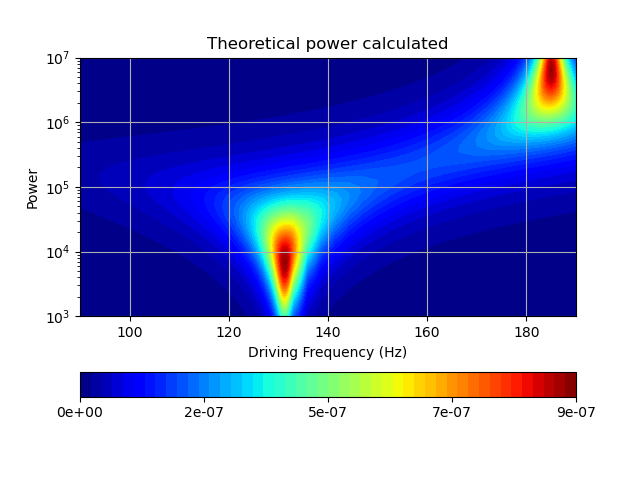

In [11]:
plt.figure()
plt.contourf(f1_grid, r1_grid, power1_th, 50, cmap=cmap)
locator = ticker.LinearLocator(numticks=5)
cbar = plt.colorbar(orientation="horizontal", format="%.e", ticks=locator)
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Theoretical power calculated")
# plt.legend()
plt.yscale("log")
plt.grid()
plt.show()

In [12]:
fig = go.Figure(data=[
    go.Surface(x=f1_grid, y=jnp.log10(r1_grid), z=power1_exp*1.e6, opacity=0.5, colorscale = 'jet'),
    go.Surface(x=f1_grid, y=jnp.log10(r1_grid), z=power1_th*1.e6, opacity = .5, showscale=False, colorscale="jet"),

])

def update(fig):
    fig.update_layout(scene = dict(
                      xaxis=dict(
                          title=dict(
                              text='Frequency, f [Hz]'
                          )
                      ),
                      yaxis=dict(
                          title=dict(
                              text='Resistance, R [log10(Ohm)]'
                          )
                      ),
                      zaxis=dict(
                          title=dict(
                              text='Power [muW]'
                          )
                      ),
                    ),
                    width=700,
                    margin=dict(r=20, b=10, l=10, t=10))
update(fig)
fig.show()

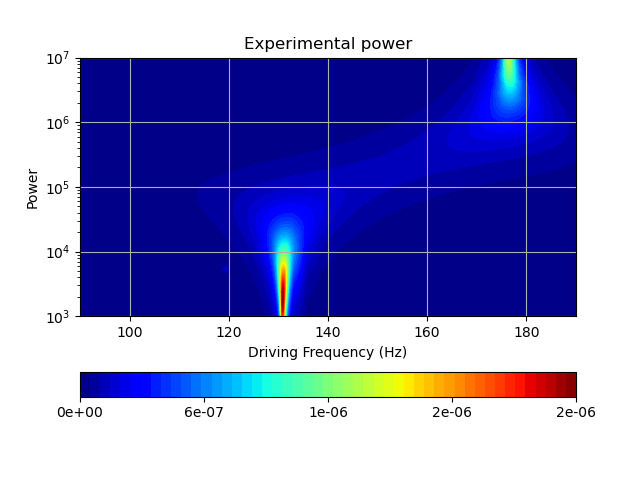

In [13]:
plt.figure()
plt.contourf(f1_grid, r1_grid, power1_exp, 50, cmap=cmap)
locator = ticker.LinearLocator(numticks=5)
cbar = plt.colorbar(orientation="horizontal", format="%.e", ticks=locator)
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Experimental power")
#plt.legend()
plt.yscale("log")
plt.grid()
plt.show()

In [14]:
fig = go.Figure(data=[
    go.Surface(x=f1_grid, y=jnp.log10(r1_grid), z=(power1_th - power1_exp)*1.e6, opacity=0.5, colorscale="jet"),

])

def update(fig):
    fig.update_layout(scene = dict(
                      xaxis=dict(
                          title=dict(
                              text='Frequency, f [Hz]'
                          )
                      ),
                      yaxis=dict(
                          title=dict(
                              text='Resistance, R [log10(Ohm)]'
                          )
                      ),
                      zaxis=dict(
                          title=dict(
                              text='Power [muW]'
                          )
                      ),
                    ),
                    width=700,
                    margin=dict(r=20, b=10, l=10, t=10))
update(fig)
fig.show()

/tmp/ipykernel_2175498/1060603582.py:14: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



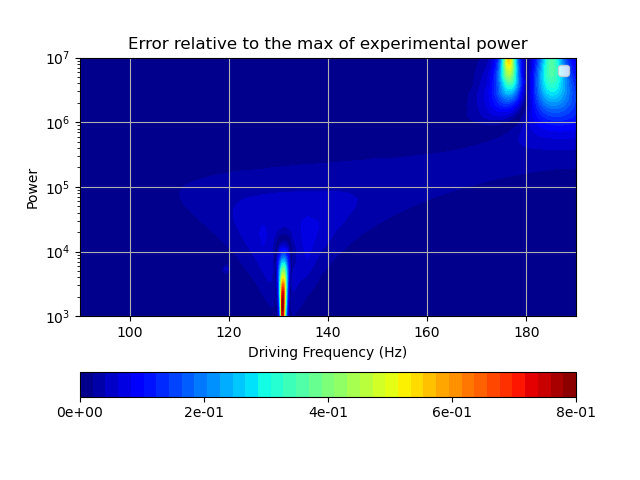

In [15]:
plt.figure()
plt.contourf(
    f_list,
    r_list,
    abs(power1_exp - power1_th) / (power1_exp.max(axis=1).max(axis=0)),
    50,
    cmap=cmap,
)
locator = ticker.LinearLocator(numticks=5)
cbar = plt.colorbar(orientation="horizontal", format="%.e", ticks=locator)
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Error relative to the max of experimental power")
plt.legend()
plt.yscale("log")
plt.grid()
plt.show()

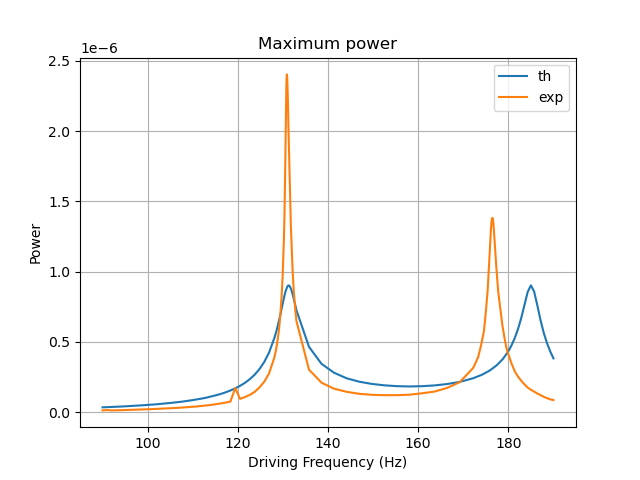

In [16]:
plt.figure()
plt.plot(f_list, power1_th.max(axis=0), label="th")
plt.plot(f_list, power1_exp.max(axis=0), label="exp")
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Maximum power")
plt.legend()
plt.grid()
plt.show()

In [17]:
w2_grid, r2_grid, power2_th = vpower(w_list, r_list, ProtoCaracsOpt2)
f2_grid = w2_grid / (2. * jnp.pi)

/tmp/ipykernel_2175498/3965817321.py:8: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



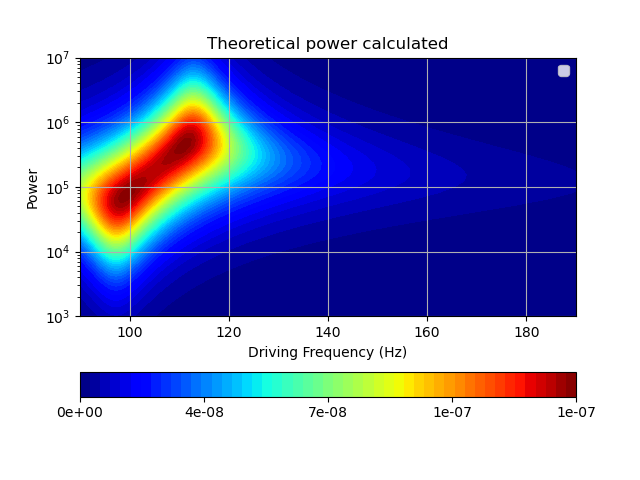

In [18]:
plt.figure()
plt.contourf(f2_grid, r2_grid, power2_th, 50, cmap=cmap)
locator = ticker.LinearLocator(numticks=5)
cbar = plt.colorbar(orientation="horizontal", format="%.e", ticks=locator)
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Theoretical power calculated")
plt.legend()
plt.yscale("log")
plt.grid()
plt.show()

In [19]:
fig = go.Figure(data=[
    go.Surface(x=f2_grid, y=jnp.log10(r2_grid), z=power2_exp*1.e6, opacity=0.5),
    go.Surface(x=f2_grid, y=jnp.log10(r2_grid), z=power2_th*1.e6, opacity = .5, showscale=False, colorscale="jet"),

])

def update(fig):
    fig.update_layout(scene = dict(
                      xaxis=dict(
                          title=dict(
                              text='Frequency, f [Hz]'
                          )
                      ),
                      yaxis=dict(
                          title=dict(
                              text='Resistance, R [log10(Ohm)]'
                          )
                      ),
                      zaxis=dict(
                          title=dict(
                              text='Power [muW]'
                          )
                      ),
                    ),
                    width=700,
                    margin=dict(r=20, b=10, l=10, t=10))
update(fig)
fig.show()

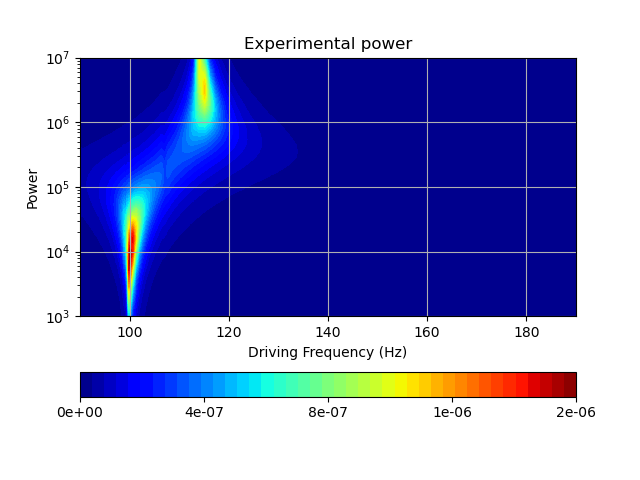

In [20]:
plt.figure()
plt.contourf(f_list, r_list, power2_exp, 50, cmap=cmap)
locator = ticker.LinearLocator(numticks=5)
cbar = plt.colorbar(orientation="horizontal", format="%.e", ticks=locator)
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Experimental power")
#plt.legend()
plt.yscale("log")
plt.grid()
plt.show()

In [ ]:
fig = go.Figure(data=[
    go.Surface(x=f2_grid, y=jnp.log10(r2_grid), z=(power2_th - power2_exp)*1.e6, opacity=0.5, colorscale="jet"),

])

def update(fig):
    fig.update_layout(scene = dict(
                      xaxis=dict(
                          title=dict(
                              text='Frequency, f [Hz]'
                          )
                      ),
                      yaxis=dict(
                          title=dict(
                              text='Resistance, R [log10(Ohm)]'
                          )
                      ),
                      zaxis=dict(
                          title=dict(
                              text='Power [muW]'
                          )
                      ),
                    ),
                    width=700,
                    margin=dict(r=20, b=10, l=10, t=10))
update(fig)
fig.show()

/tmp/ipykernel_2175498/2993527799.py:14: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



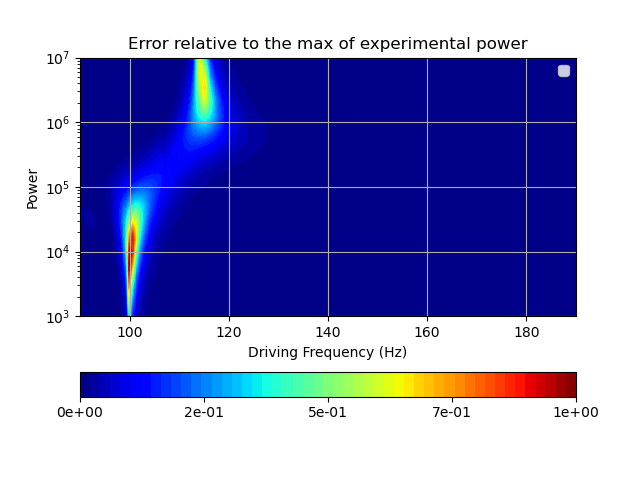

In [22]:
plt.figure()
plt.contourf(
    f_list,
    r_list,
    abs(power2_exp - power2_th) / (power2_exp.max(axis=1).max(axis=0)),
    50,
    cmap=cmap,
)
locator = ticker.LinearLocator(numticks=5)
cbar = plt.colorbar(orientation="horizontal", format="%.e", ticks=locator)
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Error relative to the max of experimental power")
plt.legend()
plt.yscale("log")
plt.grid()
plt.show()

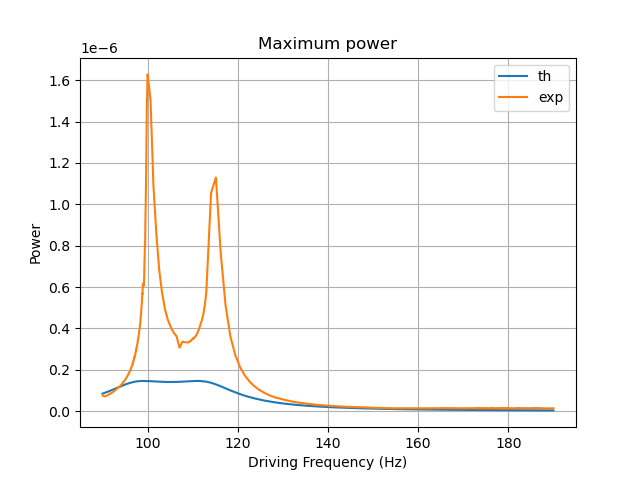

In [23]:
plt.figure()
plt.plot(f_list, power2_th.max(axis=0), label="th")
plt.plot(f_list, power2_exp.max(axis=0), label="exp")
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Maximum power")
plt.legend()
plt.grid()
plt.show()